In [1]:
%pip install -q --break-system-packages -r requirements.txt

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
Note: you may need to restart the kernel to use updated packages.


In [2]:
import hashlib
import json
import os
import re
import shutil
import time

os.environ["HF_HOME"] = "models/hf"  # must be set before any Hugging Face library is imported

import bm25s
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import Stemmer
from datasets import Dataset
from mlx_lm import batch_generate, load
from sentence_transformers import SentenceTransformer, SentenceTransformerTrainer, SentenceTransformerTrainingArguments, losses
from sentence_transformers.training_args import BatchSamplers
from sklearn.model_selection import train_test_split
from tqdm import tqdm
from transformers.trainer_utils import get_last_checkpoint

SEED = 0
DATA_PATH = "data/data.parquet"
SPLITS_PATH = "data/splits.parquet"
HISTORIES_PATH = "data/histories.parquet"
BASE_MODEL = "BAAI/bge-small-en-v1.5"
QUERY_PREFIX = "Represent this sentence for searching relevant passages: "
MAX_LENGTH = 64
BATCH_SIZE = 128
LEARNING_RATE = 2e-5
WARMUP_RATIO = 0.1
SAVE_STEPS = 250
KEYWORD_SHARE = 0.30  # keyword examples added, as a share of the question examples
OPENING_CAP = 0.10  # no three-word opening may start more than 10% of the questions
NEGATIVES_PATH = "models/checkpoints/hard_negatives.parquet"


def seeded_hash(key):
    return int(hashlib.md5(f"{SEED}:{key}".encode()).hexdigest()[:15], 16)


BLUE = "#2a78d6"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#898781",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "axes.labelcolor": "#52514e",
    "axes.titlelocation": "left", "axes.titlesize": 11,
})
for folder in ["results/rankings", "results/speed", "models/checkpoints", "models/trained"]:
    os.makedirs(folder, exist_ok=True)

/Users/adiram/.local/share/uv/python/cpython-3.11.15-macos-aarch64-none/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1124 12:47:55.572000 22871 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
/var/folders/67/5h9frnrs01j1mx2dt92t8r480000gn/T/ipykernel_22871/753039619.py:17: DeprecationWarning: Importing from 'sentence_transformers.losses' is deprecated and will be removed in a future version. Please use 'sentence_transformers.sentence_transformer.losses' instead.
  from sentence_transformers import SentenceTransformer, SentenceTransformerTrainer, SentenceTransformerTrainingArguments, losses
/var/folders/67/5h9frnrs01j1mx2dt92t8r480000gn/T/ipykernel_22871/753039619.py:18: DeprecationWarning: Importing from 'sentence_transfo

In [3]:
data = pd.read_parquet(DATA_PATH)

if os.path.exists(SPLITS_PATH):
    splits = pd.read_parquet(SPLITS_PATH)
else:
    rest, test_qids = train_test_split(data["qid"], test_size=2_000, random_state=SEED)
    train_qids, validation_qids = train_test_split(rest, test_size=500, random_state=SEED)
    splits = pd.DataFrame({"qid": data["qid"], "split": "train"})
    splits.loc[splits["qid"].isin(validation_qids), "split"] = "validation"
    splits.loc[splits["qid"].isin(test_qids), "split"] = "test"
    splits.to_parquet(SPLITS_PATH, index=False)
print(splits["split"].value_counts().to_string())

split
train         297500
test            2000
validation       500


In [4]:
SYSTEM = """You rewrite search-engine queries into questions a person would ask an AI assistant that searches their own browsing history.

You will get the keyword query someone typed and the title and URL of the page they clicked. Imagine that same person days later, trying to find that page again by asking the assistant in plain, everyday words.

Rules:
- Write one complete, grammatical question or request, 6 to 20 words, in casual language. Ask only one thing.
- Refer to the page as something they already saw ("that article", "the recipe I found", "the video I watched"), and vary how you do it.
- Vary how the question starts, as the examples do. Most questions should not start with "Where".
- Keep the main name a person would remember, such as the show, product, person or place, so the page can still be found. Describe the rest loosely, the way people do when half-remembering.
- Never copy three or more words in a row from the page title.
- Name the website only when a person would naturally remember it, like a video on YouTube or a listing on Zillow. Most questions should not name the site.
- When the title is vague, use the URL to work out what the page is about. Names in the URL, like a Wikipedia article name, are fine to use, but never copy ID numbers, codes or file names.
- Use only information in the query, title or URL. Do not invent details like dates, times, prices or reasons.
- Output only the question, with no quotes or explanation."""

# Llama gets its own examples, so its phrasing is not copied from Qwen's.
LLAMA_EXAMPLES = [
    ("eiffel tower height", "Eiffel Tower - Wikipedia", "en.wikipedia.org/wiki/Eiffel_Tower",
     "How tall did that Eiffel Tower article say it was?"),
    ("nike running shoes women", "Women's Running Shoes. Nike.com", "nike.com/w/womens-running-shoes",
     "Show me the women's running shoes I was browsing on Nike."),
    ("sourdough starter", "How to Make a Sourdough Starter From Scratch", "kingarthurbaking.com/recipes/sourdough-starter-recipe",
     "Can you find the guide I read on making a sourdough starter?"),
]
LLAMA = "mlx-community/Meta-Llama-3.1-8B-Instruct-4bit"
llama, llama_tokenizer = load(LLAMA)


def llama_prompt(query, title, url):
    messages = [{"role": "system", "content": SYSTEM}]
    for q, t, u, answer in LLAMA_EXAMPLES:
        messages.append({"role": "user", "content": f"Query: {q}\nPage title: {t}\nURL: {u}"})
        messages.append({"role": "assistant", "content": answer})
    messages.append({"role": "user", "content": f"Query: {query}\nPage title: {title}\nURL: {url}"})
    prompt = llama_tokenizer.apply_chat_template(messages, add_generation_prompt=True, tokenize=False)
    return llama_tokenizer.encode(prompt, add_special_tokens=False)  # the template already starts with the BOS token

Fetching 6 files: 100%|██████████| 6/6 [07:49<00:00, 78.29s/it] 


In [5]:
def save(df):
    assert df["qid"].is_unique
    assert df["answer_did"].is_unique
    assert all(did in clicks for did, clicks in zip(df["answer_did"], df["clicked_dids"]))
    assert (df["title"].str.strip() != "").all() and (df["url"].str.strip() != "").all()
    df.to_parquet(DATA_PATH, compression="zstd", index=False)
    print(f"saved {len(df):,} rows, {os.path.getsize(DATA_PATH) / 1e6:.1f} MB")


held_out = data["qid"].isin(splits.loc[splits["split"] != "train", "qid"])
todo = data.index[held_out & data["test_question"].isna()]
print(f"{held_out.sum():,} validation and test rows, {len(todo):,} still need a Llama question")

for start in tqdm(range(0, len(todo), 500)):
    rows = data.loc[todo[start:start + 500]]
    out = batch_generate(llama, llama_tokenizer, [llama_prompt(r.query, r.title, r.url) for r in rows.itertuples()],
                         max_tokens=40, return_logprobs=True, completion_batch_size=64, prefill_batch_size=64)
    data.loc[rows.index, "test_question"] = [t.strip().split("\n")[0].strip() for t in out.texts]
    data.loc[rows.index, "test_score"] = [sum(lp) / len(lp) if lp else float("nan") for lp in out.logprobs]
    save(data)
assert data.loc[held_out, "test_question"].notna().all() and data.loc[~held_out, "test_question"].isna().all()

2,500 validation and test rows, 2,500 still need a Llama question


 20%|██        | 1/5 [03:24<13:37, 204.47s/it]

saved 300,000 rows, 29.0 MB


 40%|████      | 2/5 [06:51<10:18, 206.06s/it]

saved 300,000 rows, 29.0 MB


 60%|██████    | 3/5 [10:23<06:57, 208.78s/it]

saved 300,000 rows, 29.0 MB


 80%|████████  | 4/5 [13:59<03:31, 211.52s/it]

saved 300,000 rows, 29.0 MB


100%|██████████| 5/5 [17:36<00:00, 211.24s/it]

saved 300,000 rows, 29.1 MB


Qwen   mean 11.2 words, 100.0% within 6-20 words,  4.4% copy 4+ title words, 0 duplicates
Llama  mean 11.7 words, 100.0% within 6-20 words,  6.1% copy 4+ title words, 0 duplicates
Llama test_score: median -0.413, Qwen train_score: median -0.167
Qwen opening  Qwen %    Llama opening  Llama %
      i need    22.5       what's the     43.5
      i want    15.0         what are     13.5
    what was    13.9        what does      8.6
   where can     9.9           how do      6.2
 i'm looking     4.1         what was      3.2
    what did     3.8          what is      2.8
   where was     3.8 what information      2.4
   where did     3.2        what were      2.4
where's that     2.8         what did      2.0
  i remember     2.8         where is      1.0


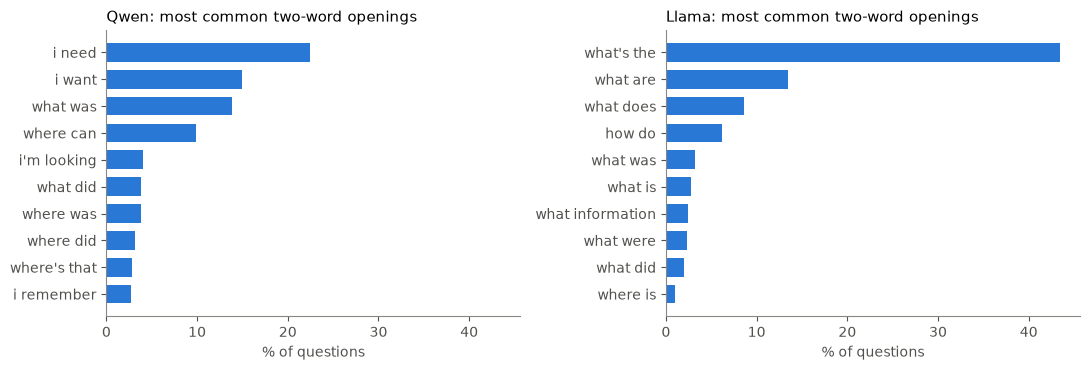


query  www.medicalmarijuanapa.gov
title  PA.gov | health.pa.gov/My%20Health/Diseases%20and%20Conditions/M-P/MedicalMarijuana/Pages/default.aspx
Qwen   I need that page about medical marijuana rules in Pennsylvania again.
Llama  What's the information on medical marijuana that I found on the Pennsylvania health website?

query  f.13 in sap
title  What is GR IR Clearing? Why is F.13 Run? | sap.ittoolbox.com/groups/technical-functional/sap-acct/what-is-gr-ir-clearing-why-is-f13-run-5133883
Qwen   What was that SAP F.13 explanation I read about clearing?
Llama  What does F.13 do in SAP accounting?

query  torrus
title  Torus | en.wikipedia.org/wiki/Torus
Qwen   What was that geometry page I read about a torus?
Llama  What is that shape called that looks like a doughnut?

query  is a living trust revocable or irrevocable
title  What is a Revocable Trust versus Irrevocable Trust | dummies.com/personal-finance/estate-planning/revocable-versus-irrevocable-trusts
Qwen   I was reading about liv

In [6]:
def copies_title(question, title):
    # True if the question repeats four or more consecutive title words.
    t = re.findall(r"\w+", title.lower())
    q = " " + " ".join(re.findall(r"\w+", question.lower())) + " "
    return any(" " + " ".join(t[i:i + 4]) + " " in q for i in range(len(t) - 3))


# Llama and Qwen questions for the same validation and test pages.
both = data[held_out]
openings = {}
for name, column in [("Qwen", "train_question"), ("Llama", "test_question")]:
    words = both[column].str.split().str.len()
    copies = np.mean([copies_title(q, t) for q, t in zip(both[column], both["title"])])
    print(f"{name:5}  mean {words.mean():4.1f} words, {words.between(6, 20).mean():5.1%} within 6-20 words, "
          f"{copies:5.1%} copy 4+ title words, {both[column].duplicated().sum()} duplicates")
    openings[name] = both[column].str.lower().str.split().str[:2].str.join(" ").value_counts().head(10) / len(both) * 100
print(f"Llama test_score: median {both['test_score'].median():.3f}, Qwen train_score: median {both['train_score'].median():.3f}")

side_by_side = pd.DataFrame({"Qwen opening": openings["Qwen"].index, "Qwen %": openings["Qwen"].values.round(1),
                             "Llama opening": openings["Llama"].index, "Llama %": openings["Llama"].values.round(1)})
print(side_by_side.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True)
for ax, name in zip(axes, ["Qwen", "Llama"]):
    ax.barh(openings[name].index, openings[name].values, color=BLUE, height=0.7)
    ax.invert_yaxis()
    ax.set(title=f"{name}: most common two-word openings", xlabel="% of questions")
plt.tight_layout()
plt.savefig("results/llama_vs_qwen_openings.png", dpi=200, bbox_inches="tight")
plt.show()

for row in both.sample(8, random_state=SEED).itertuples():
    print(f"\nquery  {row.query}\ntitle  {row.title} | {row.url}\nQwen   {row.train_question}\nLlama  {row.test_question}")

In [7]:
entry_text = dict(zip(data["answer_did"], data["title"] + " | " + data["url"]))
all_dids = data["answer_did"].to_numpy()
did_position = {d: i for i, d in enumerate(all_dids)}

stemmer = Stemmer.Stemmer("english")
retriever = bm25s.BM25(k1=1.2, b=0.75)
retriever.index(bm25s.tokenize([entry_text[d] for d in all_dids], stopwords="en", stemmer=stemmer))

In [8]:
LOOKALIKES = 100
RANDOM_FILLERS = 99


def build_history(qid, answer_did, clicked):
    # Look-alikes: the pages BM25 finds most similar to the answer's own entry, skipping clicked pages.
    tokens = bm25s.tokenize([entry_text[answer_did]], stopwords="en", stemmer=stemmer, return_ids=False, show_progress=False)[0]
    scores = retriever.get_scores(tokens)
    lookalikes = []
    for i in np.argsort(-scores, kind="stable")[:LOOKALIKES + len(clicked)]:
        if all_dids[i] not in clicked and len(lookalikes) < LOOKALIKES:
            lookalikes.append(all_dids[i])
    zero_scores = sum(scores[did_position[d]] == 0 for d in lookalikes)

    rng = np.random.default_rng(seeded_hash(qid) % 2**32)
    chosen = set(lookalikes) | {answer_did}
    fillers = []
    while len(fillers) < RANDOM_FILLERS:
        d = all_dids[rng.integers(len(all_dids))]
        if d not in clicked and d not in chosen:
            fillers.append(d)
            chosen.add(d)

    history = [answer_did] + lookalikes + fillers
    history.sort(key=lambda d: seeded_hash(qid + d))
    assert len(set(history)) == 200 and sum(d in clicked for d in history) == 1
    return history, zero_scores


if os.path.exists(HISTORIES_PATH):
    histories = pd.read_parquet(HISTORIES_PATH)
else:
    held = data[held_out]
    results = [build_history(r.qid, r.answer_did, set(r.clicked_dids)) for r in tqdm(held.itertuples(), total=len(held))]
    histories = pd.DataFrame({"qid": held["qid"].values, "history_dids": [h for h, _ in results]})
    zero = np.array([z for _, z in results])
    print(f"look-alikes with no word in common with the answer: {zero.sum() / (LOOKALIKES * len(zero)):.2%}, "
          f"{(zero > 0).mean():.1%} of histories have some")
    histories.to_parquet(HISTORIES_PATH, index=False)
print(f"{len(histories):,} histories")

for row in data[held_out].merge(histories, on="qid").head(2).itertuples():
    print(f"\nquestion  {row.test_question}\nanswer    {entry_text[row.answer_did]}")
    for d in list(row.history_dids)[:8]:
        print(f"   {'*' if d == row.answer_did else ' '} {entry_text[d]}")
    print("   ...")

100%|██████████| 2500/2500 [00:16<00:00, 150.59it/s]

look-alikes with no word in common with the answer: 0.00%, 0.0% of histories have some
2,500 histories

question  What is that Straight Talk company's customer service policy called?
answer    ABOUT STRAIGHT TALK | straighttalk.com/wps/portal/home
     WHAT WOULD YOU LIKE TO DO? | straighttalk.com/wps/portal/home/Activate/byop
     Chief of Psychiatry | bcm.edu/healthcare/care-centers/psychiatry/clinics/ben-taub-harris-health-system
     War for the Planet of the Apes  ( 2017) | imdb.com/title/tt3450958
     Business | gwinnettcounty.com/portal/gwinnett/Home
     CalWORKs | dpss.lacounty.gov/wps/portal/dpss/main/programs-and-services/calworks
     Got questions? | portal.eyemedvisioncare.com/wps/portal/em/eyemed/members/faqglossary
   * ABOUT STRAIGHT TALK | straighttalk.com/wps/portal/home
     Callie Torres | greysanatomy.wikia.com/wiki/Callie_Torres
   ...

question  How do I use arrays within arrays in JavaScript?
answer    JavaScript Arrays | w3schools.com/js/js_arrays.asp
     AS

In [ ]:
del llama, llama_tokenizer  # free the Mac's memory for training
data = data.merge(splits, on="qid")

validation_rows = data[data["split"] == "validation"].merge(histories, on="qid").reset_index(drop=True)
test_rows = data[data["split"] == "test"].merge(histories, on="qid").reset_index(drop=True)
for rows in [validation_rows, test_rows]:
    rows["history_dids"] = rows["history_dids"].map(list)
    assert rows["test_question"].notna().all()
    assert all(len(h) == 200 and a in h for a, h in zip(rows["answer_did"], rows["history_dids"]))

# Tie-break key for every page that appears in a history.
did_hash = {d: seeded_hash(d) for h in pd.concat([validation_rows, test_rows])["history_dids"] for d in h}
print(data["split"].value_counts().to_string())
print(f"{len(validation_rows):,} validation and {len(test_rows):,} test histories")

In [ ]:
held_out_clicks = set(d for clicks in pd.concat([validation_rows, test_rows])["clicked_dids"] for d in clicks)
train = data[data["split"] == "train"].reset_index(drop=True)
leaks = train["answer_did"].isin(held_out_clicks)
print(f"{len(train):,} train rows, {leaks.sum():,} dropped because their page was clicked for a validation or test query")
train = train[~leaks]

# Hard negatives may come from any leak-free training page, rewritten or not.
train_entry_dids = sorted(train["answer_did"])
missing = train["train_question"].isna()
print(f"{missing.sum():,} rows without a Qwen rewrite are dropped")
train = train[~missing].reset_index(drop=True)
filter_log = {"train_rows": int((data["split"] == "train").sum()), "leak_dropped": int(leaks.sum()),
              "no_rewrite_dropped": int(missing.sum())}
print(f"{len(train):,} training rows")

In [ ]:
title_copy = pd.Series([copies_title(q, t) for q, t in zip(train["train_question"], train["title"])], index=train.index)
print(f"copy 4+ title words: {title_copy.sum():,} rows ({title_copy.mean():.1%})")
for row in train[title_copy].sample(min(5, title_copy.sum()), random_state=SEED).itertuples():
    print(f"   {row.title[:70]!r:75} -> {row.train_question}")
train = train[~title_copy]
filter_log["title_copies"] = int(title_copy.sum())

In [ ]:
has_cjk = train["train_question"].str.contains("[぀-ヿ㐀-鿿가-힯]")
print(f"contain CJK characters: {has_cjk.sum():,} rows ({has_cjk.mean():.2%})")
for question in train.loc[has_cjk, "train_question"].head(5):
    print("   ", question)
train = train[~has_cjk]
filter_log["cjk"] = int(has_cjk.sum())

In [ ]:
# The same question pointing at two pages is ambiguous, so every copy is dropped, not just the extras.
question_key = train["train_question"].str.lower().str.strip()
duplicate = question_key.duplicated(keep=False)
print(f"duplicate questions: {duplicate.sum():,} rows ({duplicate.mean():.2%}), {question_key[duplicate].nunique():,} distinct questions")
print(question_key[duplicate].value_counts().head(10).to_string())
train = train[~duplicate].reset_index(drop=True)
filter_log["duplicates"] = int(duplicate.sum())
print(f"\n{len(train):,} training rows after title, CJK and duplicate filters")

In [ ]:
def opening(questions):
    return questions.str.lower().str.split().str[:3].str.join(" ")


def cap_openings(rows):
    # Trim each opening above the cap to its first rows in sample order.
    # Trimming shrinks the total, which lowers the cap, so repeat until nothing is above it.
    while True:
        openings = opening(rows["train_question"])
        cap = int(OPENING_CAP * len(rows))
        if openings.value_counts().iloc[0] <= cap:
            return rows
        rows = rows[openings.groupby(openings).cumcount() < cap]


capped = cap_openings(train)
before = opening(train["train_question"]).value_counts().head(10) / len(train) * 100
after = opening(capped["train_question"]).value_counts().head(10) / len(capped) * 100
print(f"opening cap removes {len(train) - len(capped):,} rows ({1 - len(capped) / len(train):.1%})")
print(pd.DataFrame({"before %": before.round(1), "after %": after.round(1)}).to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True)
for ax, top, label in [(axes[0], before, f"Before cap ({len(train):,} rows)"), (axes[1], after, f"After cap ({len(capped):,} rows)")]:
    ax.barh(top.index, top.values, color=BLUE, height=0.7)
    ax.invert_yaxis()
    ax.axvline(OPENING_CAP * 100, color="#0b0b0b", linestyle="--", linewidth=1)
    ax.set(title=label, xlabel="% of questions")
plt.tight_layout()
plt.savefig("results/ft_openings.png", dpi=200, bbox_inches="tight")
plt.show()
filter_log["opening_cap_no_cutoff"] = len(train) - len(capped)

In [ ]:
quantiles = train["train_score"].quantile([0.05, 0.10, 0.20, 0.30])
print("train_score quantiles:\n" + quantiles.round(3).to_string())
SCORE_CUTOFFS = {"none": None, "drop10": float(quantiles[0.10]), "drop20": float(quantiles[0.20])}

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(train["train_score"], bins=60, color=BLUE, edgecolor="white", linewidth=0.5)
for name in ["drop10", "drop20"]:
    ax.axvline(SCORE_CUTOFFS[name], color="#0b0b0b", linestyle="--", linewidth=1)
    ax.text(SCORE_CUTOFFS[name], ax.get_ylim()[1] * 0.9, f" {name}", color="#52514e")
ax.set(title="Qwen rewrite confidence of training rows", xlabel="Average token log-probability", ylabel="Rows")
plt.savefig("results/ft_train_score.png", dpi=200, bbox_inches="tight")
plt.show()

print("Lowest-scoring rewrites:")
for row in train.nsmallest(8, "train_score").itertuples():
    print(f"   {row.train_score:6.3f}  {row.query!r:35} -> {row.train_question}")

In [ ]:
# About 30% extra examples use the original keyword query as the question, chosen per row by seeded hash.
train["keyword"] = [seeded_hash(f"keyword:{qid}") % 100 < KEYWORD_SHARE * 100 for qid in train["qid"]]
print(f"{train['keyword'].mean():.1%} of rows also give a keyword example, e.g.")
for row in train[train["keyword"]].head(5).itertuples():
    print(f"   {row.query!r:35} | {row.train_question}")


def training_rows(cutoff_name):
    rows = train
    if SCORE_CUTOFFS[cutoff_name] is not None:
        rows = rows[rows["train_score"] >= SCORE_CUTOFFS[cutoff_name]]
    return cap_openings(rows).reset_index(drop=True)


def filters_for(cutoff_name):
    return {**filter_log, "score_cutoff": cutoff_name, "score_cutoff_value": SCORE_CUTOFFS[cutoff_name],
            "opening_cap": OPENING_CAP, "keyword_share": KEYWORD_SHARE}


for name in SCORE_CUTOFFS:
    rows = training_rows(name)
    print(f"cutoff {name:7} {len(rows):,} question rows + {rows['keyword'].sum():,} keyword rows")

In [ ]:
# Reuses the global BM25 index built for the histories. Added to the BM25 scores: -inf on every page that is not a training entry, so it is never picked.
not_training = np.where(np.isin(all_dids, train_entry_dids), 0.0, -np.inf)

In [ ]:
def mine_negative(text, clicked, key):
    tokens = bm25s.tokenize([text], stopwords="en", stemmer=stemmer, return_ids=False, show_progress=False)[0]
    if tokens:
        scores = retriever.get_scores(tokens) + not_training
        scores[[did_position[d] for d in clicked if d in did_position]] = -np.inf
        best = int(np.argmax(scores))
        if scores[best] > 0:
            return all_dids[best], True
    # No word in common with any training entry: fall back to a random training page that was not clicked.
    k = seeded_hash(key)
    while train_entry_dids[k % len(train_entry_dids)] in clicked:
        k += 1
    return train_entry_dids[k % len(train_entry_dids)], False


needed = pd.concat([
    pd.DataFrame({"qid": train["qid"], "kind": "question", "text": train["train_question"], "clicked_dids": train["clicked_dids"]}),
    pd.DataFrame({"qid": train["qid"], "kind": "keyword", "text": train["query"], "clicked_dids": train["clicked_dids"]})[train["keyword"]],
]).reset_index(drop=True)

if os.path.exists(NEGATIVES_PATH):
    mined = pd.read_parquet(NEGATIVES_PATH)
else:
    mined = pd.DataFrame({"qid": pd.Series(dtype=str), "kind": pd.Series(dtype=str),
                          "negative_did": pd.Series(dtype=str), "from_bm25": pd.Series(dtype=bool)})
todo = needed[~(needed["qid"] + ":" + needed["kind"]).isin(mined["qid"] + ":" + mined["kind"])]
print(f"{len(needed):,} examples need a hard negative, {len(todo):,} not mined yet")

for start in tqdm(range(0, len(todo), 20_000)):
    chunk = todo.iloc[start:start + 20_000]
    results = [mine_negative(r.text, set(r.clicked_dids), f"{r.qid}:{r.kind}") for r in chunk.itertuples()]
    new = pd.DataFrame({"qid": chunk["qid"], "kind": chunk["kind"],
                        "negative_did": [d for d, _ in results], "from_bm25": [b for _, b in results]})
    mined = pd.concat([mined, new], ignore_index=True)
    mined.to_parquet(NEGATIVES_PATH, index=False)

negatives = {(q, k): d for q, k, d in zip(mined["qid"], mined["kind"], mined["negative_did"])}
print(f"{(~mined['from_bm25']).mean():.2%} of negatives fell back to a random page (no shared words)")
print(f"most reused negatives:\n{mined['negative_did'].map(entry_text).value_counts().head(5).to_string()}")

In [ ]:
for row in train.sample(6, random_state=SEED).itertuples():
    print(f"question  {row.train_question}")
    print(f"positive  {entry_text[row.answer_did]}")
    print(f"negative  {entry_text[negatives[(row.qid, 'question')]]}\n")

In [ ]:
def build_examples(rows, hard_negatives):
    keyword_rows = rows[rows["keyword"]]
    columns = {
        "question": rows["train_question"].tolist() + keyword_rows["query"].tolist(),
        "positive": [entry_text[d] for d in rows["answer_did"]] + [entry_text[d] for d in keyword_rows["answer_did"]],
    }
    if hard_negatives:
        negative_dids = [negatives[(q, "question")] for q in rows["qid"]] + [negatives[(q, "keyword")] for q in keyword_rows["qid"]]
        columns["negative"] = [entry_text[d] for d in negative_dids]
    return Dataset.from_dict(columns)


def history_dids_of(rows):
    return sorted(set(d for h in rows["history_dids"] for d in h))


def encode_entries(model, dids):
    vectors = model.encode([entry_text[d] for d in dids], batch_size=256, normalize_embeddings=True,
                           convert_to_numpy=True, show_progress_bar=True)
    return dict(zip(dids, vectors))


def rank_histories(model, rows, questions, entry_vectors):
    question_vectors = model.encode(list(questions), prompt_name="query", batch_size=256,
                                    normalize_embeddings=True, convert_to_numpy=True)
    rankings = []
    for question_vector, history in zip(question_vectors, rows["history_dids"]):
        scores = np.array([entry_vectors[d] for d in history]) @ question_vector
        # Highest score first; ties broken by the seeded hash of the page id.
        order = np.lexsort((np.array([did_hash[d] for d in history]), -scores))
        rankings.append([history[i] for i in order])
    return rankings


def recall_at(rankings, answers, k):
    return float(np.mean([a in r[:k] for r, a in zip(rankings, answers)]))


def mean_reciprocal_rank(rankings, answers):
    return float(np.mean([1 / (r.index(a) + 1) for r, a in zip(rankings, answers)]))


def validation_metrics(model):
    entry_vectors = encode_entries(model, history_dids_of(validation_rows))
    rankings = rank_histories(model, validation_rows, validation_rows["test_question"], entry_vectors)
    answers = validation_rows["answer_did"]
    return {"recall@1": recall_at(rankings, answers, 1), "recall@5": recall_at(rankings, answers, 5),
            "mrr": mean_reciprocal_rank(rankings, answers)}

In [ ]:
def train_model(rows, run, seed, hard_negatives, filters):
    final_dir = f"models/trained/{run}"
    if os.path.exists(final_dir):
        with open(f"{final_dir}/training_info.json") as f:
            metrics = json.load(f)["validation"]
        print(f"{run}: already trained, validation Recall@5 {metrics['recall@5']:.3f}")
        return metrics

    checkpoint_dir = f"models/checkpoints/{run}"
    dataset = build_examples(rows, hard_negatives)
    model = SentenceTransformer(BASE_MODEL, device="mps", prompts={"query": QUERY_PREFIX})
    model.max_seq_length = MAX_LENGTH
    args = SentenceTransformerTrainingArguments(
        output_dir=checkpoint_dir, num_train_epochs=1, per_device_train_batch_size=BATCH_SIZE,
        learning_rate=LEARNING_RATE, warmup_ratio=WARMUP_RATIO, seed=seed,
        batch_sampler=BatchSamplers.NO_DUPLICATES,  # a page never appears twice in one batch
        prompts={"question": QUERY_PREFIX},
        save_strategy="steps", save_steps=SAVE_STEPS, save_total_limit=2, logging_steps=50, report_to="none",
    )
    trainer = SentenceTransformerTrainer(model=model, args=args, train_dataset=dataset,
                                         loss=losses.MultipleNegativesRankingLoss(model))
    last_checkpoint = get_last_checkpoint(checkpoint_dir) if os.path.isdir(checkpoint_dir) else None
    print(f"{run}: {len(dataset):,} examples, resuming from {last_checkpoint}")
    trainer.train(resume_from_checkpoint=last_checkpoint)

    metrics = validation_metrics(model)
    info = {"base_model": BASE_MODEL, "seed": seed, "question_rows": len(rows), "keyword_rows": int(rows["keyword"].sum()),
            "examples": len(dataset), "hard_negatives": hard_negatives, "batch_size": BATCH_SIZE,
            "learning_rate": LEARNING_RATE, "warmup_ratio": WARMUP_RATIO, "max_seq_length": MAX_LENGTH,
            "filters": filters, "validation": metrics}
    # Save to a temporary folder and rename, so a crash mid-save never leaves a folder that looks finished.
    model.save(final_dir + ".tmp", safe_serialization=True)
    with open(f"{final_dir}.tmp/training_info.json", "w") as f:
        json.dump(info, f, indent=2)
    os.rename(final_dir + ".tmp", final_dir)
    shutil.rmtree(checkpoint_dir)
    print(f"{run}: validation Recall@5 {metrics['recall@5']:.3f}")
    return metrics

In [ ]:
selection = {}
for name in SCORE_CUTOFFS:
    selection[f"{name}, hard negatives"] = train_model(training_rows(name), f"select_{name}_hard", 0, True, filters_for(name))

best_cutoff = "none"
for name in SCORE_CUTOFFS:
    if selection[f"{name}, hard negatives"]["recall@5"] > selection[f"{best_cutoff}, hard negatives"]["recall@5"]:
        best_cutoff = name
print(f"best train_score cutoff on validation: {best_cutoff}")

In [ ]:
selection[f"{best_cutoff}, in-batch only"] = train_model(training_rows(best_cutoff), f"select_{best_cutoff}_inbatch", 0, False,
                                                         filters_for(best_cutoff))
hard = selection[f"{best_cutoff}, hard negatives"]["recall@5"]
in_batch = selection[f"{best_cutoff}, in-batch only"]["recall@5"]
USE_HARD_NEGATIVES = hard >= in_batch  # fall back to in-batch only if hard negatives hurt
print(f"validation Recall@5: hard negatives {hard:.3f}, in-batch only {in_batch:.3f} -> hard negatives: {USE_HARD_NEGATIVES}")

print(pd.DataFrame(selection).T.round(3).to_string())
fig, ax = plt.subplots(figsize=(8, 3))
names = list(selection)
values = [selection[n]["recall@5"] * 100 for n in names]
ax.barh(names, values, color=BLUE, height=0.6)
ax.invert_yaxis()
for i, v in enumerate(values):
    ax.text(v + 0.3, i, f"{v:.1f}", va="center", color="#52514e")
ax.set(title="Selection runs (seed 0)", xlabel="Validation Recall@5 (%)")
plt.savefig("results/ft_selection.png", dpi=200, bbox_inches="tight")
plt.show()

In [ ]:
final_rows = training_rows(best_cutoff)
final_filters = filters_for(best_cutoff)

# The seed-0 final model has exactly the config of the chosen selection run, so it is copied instead of trained again.
chosen = f"models/trained/select_{best_cutoff}_{'hard' if USE_HARD_NEGATIVES else 'inbatch'}"
if not os.path.exists("models/trained/bge_ft_seed0"):
    shutil.copytree(chosen, "models/trained/bge_ft_seed0")

for seed in [1, 2]:
    train_model(final_rows, f"bge_ft_seed{seed}", seed, USE_HARD_NEGATIVES, final_filters)
for n in [25_000, 100_000]:
    train_model(final_rows.head(n), f"bge_ft_{n // 1000}k_seed0", 0, USE_HARD_NEGATIVES, final_filters)

In [ ]:
FINAL_RUNS = ["bge_ft_seed0", "bge_ft_seed1", "bge_ft_seed2", "bge_ft_25k_seed0", "bge_ft_100k_seed0"]
SOURCES = [("validation", "llama", "test_question"), ("test", "llama", "test_question"),
           ("test", "qwen", "train_question"), ("test", "keyword", "query")]


def write_rankings(run):
    path = f"results/rankings/{run}.parquet"
    if os.path.exists(path):
        print(f"{run}: rankings already written")
        return
    model = SentenceTransformer(f"models/trained/{run}", device="mps")
    entry_vectors = encode_entries(model, history_dids_of(pd.concat([validation_rows, test_rows])))
    parts = []
    for split, source, column in SOURCES:
        rows = validation_rows if split == "validation" else test_rows
        rankings = rank_histories(model, rows, rows[column], entry_vectors)
        parts.append(pd.DataFrame({"qid": rows["qid"], "split": split, "source": source, "ranked_dids": rankings}))
        print(f"{run} {split:10} {source:7} Recall@5 {recall_at(rankings, rows['answer_did'], 5):.3f}")
    pd.concat(parts, ignore_index=True).to_parquet(path, index=False)


def write_speed(run):
    path = f"results/speed/{run}.json"
    if os.path.exists(path):
        print(f"{run}: speed already measured")
        return
    model = SentenceTransformer(f"models/trained/{run}", device="cpu")
    rows = test_rows.head(500)
    model.encode(["warm up"], prompt_name="query")

    entries = [entry_text[d] for h in rows["history_dids"].head(50) for d in h]
    start = time.perf_counter()
    entry_vectors = model.encode(entries, batch_size=256, normalize_embeddings=True, convert_to_numpy=True)
    entry_ms = (time.perf_counter() - start) * 1000 / len(entries)

    # Scoring cost does not depend on which 200 entries, so the 500 questions reuse the 50 encoded histories.
    histories_vectors = entry_vectors.reshape(50, 200, -1)
    start = time.perf_counter()
    for i, question in enumerate(tqdm(rows["test_question"], desc=f"{run} CPU timing")):
        question_vector = model.encode(question, prompt_name="query", normalize_embeddings=True, convert_to_numpy=True)
        np.argsort(-(histories_vectors[i % 50] @ question_vector))
    question_ms = (time.perf_counter() - start) * 1000 / len(rows)

    with open(path, "w") as f:
        json.dump({"entry_ms": entry_ms, "question_ms": question_ms}, f, indent=2)
    print(f"{run}: {entry_ms:.2f} ms per entry, {question_ms:.2f} ms per question on CPU")


for run in FINAL_RUNS:
    write_rankings(run)
    write_speed(run)

In [ ]:
final_metrics = {}
for run in FINAL_RUNS:
    with open(f"models/trained/{run}/training_info.json") as f:
        info = json.load(f)
    final_metrics[run] = {"question_rows": info["question_rows"], **info["validation"]}
print(pd.DataFrame(final_metrics).T.round(3).to_string())

best_run = "bge_ft_seed0"
for run in ["bge_ft_seed1", "bge_ft_seed2"]:
    if final_metrics[run]["recall@5"] > final_metrics[best_run]["recall@5"]:
        best_run = run
if os.path.exists("models/trained/history-retriever"):
    shutil.rmtree("models/trained/history-retriever")
shutil.copytree(f"models/trained/{best_run}", "models/trained/history-retriever")
print(f"best on validation: {best_run}, copied to models/trained/history-retriever")

In [ ]:
sizes = [final_metrics[r]["question_rows"] for r in ["bge_ft_25k_seed0", "bge_ft_100k_seed0", "bge_ft_seed0"]]
recalls = [final_metrics[r]["recall@5"] * 100 for r in ["bge_ft_25k_seed0", "bge_ft_100k_seed0", "bge_ft_seed0"]]
seed_recalls = [final_metrics[f"bge_ft_seed{s}"]["recall@5"] * 100 for s in [0, 1, 2]]

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(sizes, recalls, color=BLUE, marker="o")
ax.scatter([sizes[-1]] * 3, seed_recalls, color="#898781", zorder=3, s=14, label="seeds 0, 1, 2")
for x, y in zip(sizes, recalls):
    ax.text(x, y + 0.4, f"{y:.1f}", ha="center", color="#52514e")
ax.set_xscale("log")
ax.set(title="Learning curve (seed 0)", xlabel="Question rows in training (log scale)", ylabel="Validation Recall@5 (%)")
ax.legend(frameon=False)
plt.savefig("results/ft_learning_curve.png", dpi=200, bbox_inches="tight")
plt.show()